# Heterogenous profile-matched analysis

This script creates 4 groups (n = 200) of participants: 
- HG (high adversity, good mental health)
- HP (high adversity, poor mental health)
- LG (low adversity, good mental health)
- LP (low adversity, poor mental health)

Then, the number and weight of risk- and health-aligned M&G edges are compared across groups. Lastly, risk- and health-aligned M&G connections are characterized by type and location.

Example data is provided in order to run the code. All original data is avaliable on the NBDC Data Hub (https://www.nbdc-datahub.org/).

Written by: Alexa Mousley (alexa.mousley@mrc-cbu.cam.ac.uk)
*October 2026*

In [12]:
### Import packages ###

from A_config import *                            # Import custom paths
from A_functions import *                         # Import custom function
import os                                         # For combining paths
import numpy as np                                # Basic requirements 
import pandas as pd                               # Basic requirements 
import nibabel as nib                             # Load FreeSurfer surface geometry files

In [3]:
### Load data ###

# Associated data
associated_data = pd.read_csv(os.path.join(data_dir,"associated_data_example.csv"))

# Networks
all_connectomes =  np.load(os.path.join(data_dir, "connectomes.npz"))['connectomes']
# Pull only networks for those with matching associated data
connectomes = all_connectomes[:,:,associated_data['imaging_index'].values]

# Matrices of edges that are stable for each PLS
adversity_edge_matrix = np.load(os.path.join(data_dir, 'adversity_edge_matrix_example.npy'))
mental_health_edge_matrix = np.load(os.path.join(data_dir, 'mental_health_edge_matrix_example.npy'))
genetics_LV1_edge_matrix = np.load(os.path.join(data_dir, 'genetics_LV1_edge_matrix_example.npy'))
genetics_LV2_edge_matrix = np.load(os.path.join(data_dir, 'genetics_LV2_edge_matrix_example.npy'))

# Vertices and faces for plotting surfaces
lh_vertices, lh_faces = nib.freesurfer.read_geometry(os.path.join(fs_path,"lh.pial"))
rh_vertices, rh_faces = nib.freesurfer.read_geometry(os.path.join(fs_path,"rh.pial"))#

# Atlas
atlas = pd.read_pickle(os.path.join(data_dir,'brainnetome.pkl'))
atlas_coords = atlas['coordinates']
region_labels = np.array(atlas['region_label'])
region_lobes = np.array(atlas['lobe'])
distances = atlas['euclidean_distance']

# Rich club nodes
rich_club = np.load(os.path.join(data_dir,'rich_club_example.npy'))

### Set up data ###

# Define number of nodes and number of participants
nnodes, _, nsub = connectomes.shape 

# Define number of total possible edges
n_edges = int((nnodes*(nnodes-1))/2)    

# Create a dict for plotting data
plot_args = dict(atlas_coords=atlas_coords, lh_vertices=lh_vertices,region_labels=region_labels,
                 region_lobes=region_lobes,distances=distances,
                 rh_vertices=rh_vertices, save_path=save_dir)

Possible participants (top/bottom 30% of adversity and MH):
    HP: 1,049
    HG: 482
    LP: 384
    LG: 1,092

Anchor (smallest) group: LP -> at most 384 matched sets possible
Matched sets found: 200

Adversity contrast (should DIFFER on adversity, MATCH on MH / age / sex):
    HP vs LP: adversity t = 30.51, p = 2.98e-106 | MH t = 0.29, p = 0.772 | age t = -0.01, p = 0.995 | sex t = 0.00, p = 1.000
    HG vs LG: adversity t = 30.29, p = 2.18e-105 | MH t = 0.13, p = 0.896 | age t = 0.04, p = 0.968 | sex t = 1.11, p = 0.267

MH contrast (should DIFFER on MH, MATCH on adversity / age / sex):
    HP vs HG: MH t = 42.68, p = 1.32e-150 | adversity t = 0.07, p = 0.944 | age t = -0.05, p = 0.957 | sex t = -1.11, p = 0.267
    LP vs LG: MH t = 43.00, p = 1.10e-151 | adversity t = 1.09, p = 0.276 | age t = -0.01, p = 0.995 | sex t = 0.00, p = 1.000


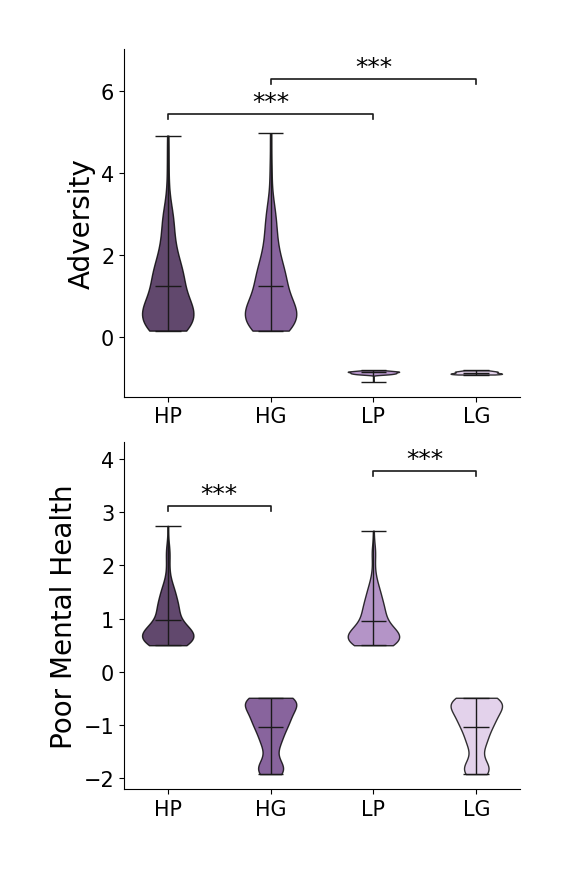

In [14]:
### Create profile-matched groups and Figure 5a ###
matching = match_adversity_mh_groups(associated_data, save_path=save_dir,
                                     quantile_threshold=0.30, nsub_target=200, caliper=0.15)
matched_index = matching['matched_index']
group_membership = matching['group_membership']

In [15]:
### Calculate and extract edge scores per group ###

overlap_masks, aligned_overlap_masks, overlap_percentages = extract_masks(
    adversity_edge_matrix, mental_health_edge_matrix, genetics_LV1_edge_matrix,
    names=['Adversity', 'Mental Health', 'Genetics'],flip=['Genetics'])

edge_group_scores, edge_group_details = get_edge_group_scores(connectomes, aligned_overlap_masks)

matched_df = pd.DataFrame({
    'group': group_membership,
    'count_risk': edge_group_details['Mental Health & Genetics']['count_risk'][matched_index],
    'count_health': edge_group_details['Mental Health & Genetics']['count_health'][matched_index],
    'weight_risk': edge_group_details['Mental Health & Genetics']['weight_risk'][matched_index],
    'weight_health': edge_group_details['Mental Health & Genetics']['weight_health'][matched_index]
})

# Choose which mask to use for analysis
mask = aligned_overlap_masks['Mental Health & Genetics']

Adversity (5,140 edges) & Mental Health (5,704 edges):
    1,349 overlapping edges, 1,077 shared edges grouped into: 372 Risk-aligned, 705 Health-aligned 

Adversity (5,140 edges) & Genetics (4,479 edges):
    1,146 overlapping edges, 777 shared edges grouped into: 332 Risk-aligned, 445 Health-aligned 

Mental Health (5,704 edges) & Genetics (4,479 edges):
    1,261 overlapping edges, 801 shared edges grouped into: 345 Risk-aligned, 456 Health-aligned 




 count_risk 
  Levene: W = 0.24, p = 0.871 (equal variances -> One-way ANOVA + Tukey HSD)
  One-way ANOVA: F(3, 796.0) = 5.68, p = 7.46e-04, ηp² = 0.021 ***
  Post-hoc (Tukey HSD):
    HG vs HP: T = 0.24, g = 0.02, p = 0.995 ns  <-- HG
    HG vs LG: T = 3.16, g = 0.31, p = 0.009 **  <-- HG
    HG vs LP: T = -0.63, g = -0.06, p = 0.921 ns  <-- HG
    HP vs LG: T = 2.92, g = 0.29, p = 0.019 *
    HP vs LP: T = -0.88, g = -0.09, p = 0.817 ns
    LG vs LP: T = -3.79, g = -0.37, p = 9.18e-04 ***

 count_health 
  Levene: W = 0.29, p = 0.831 (equal variances -> One-way ANOVA + Tukey HSD)
  One-way ANOVA: F(3, 796.0) = 2.30, p = 0.076, ηp² = 0.009 ns
  Post-hoc (Tukey HSD):
    HG vs HP: T = 1.21, g = 0.12, p = 0.621 ns  <-- HG
    HG vs LG: T = -1.41, g = -0.14, p = 0.492 ns  <-- HG
    HG vs LP: T = 0.00, g = 0.00, p = 1.000 ns  <-- HG
    HP vs LG: T = -2.62, g = -0.26, p = 0.044 *
    HP vs LP: T = -1.21, g = -0.12, p = 0.621 ns
    LG vs LP: T = 1.41, g = 0.14, p = 0.492 ns

 weight_ris

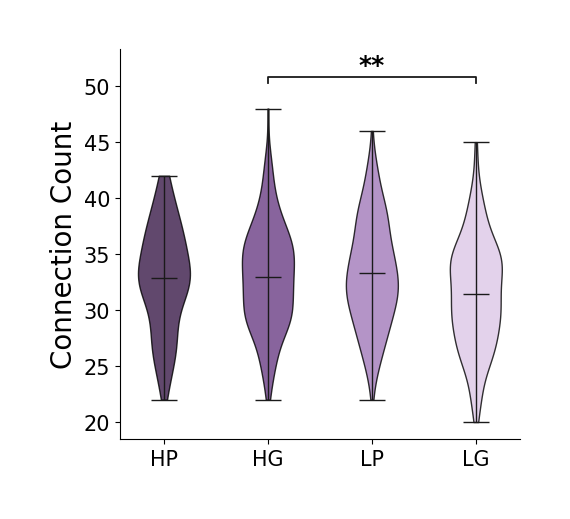

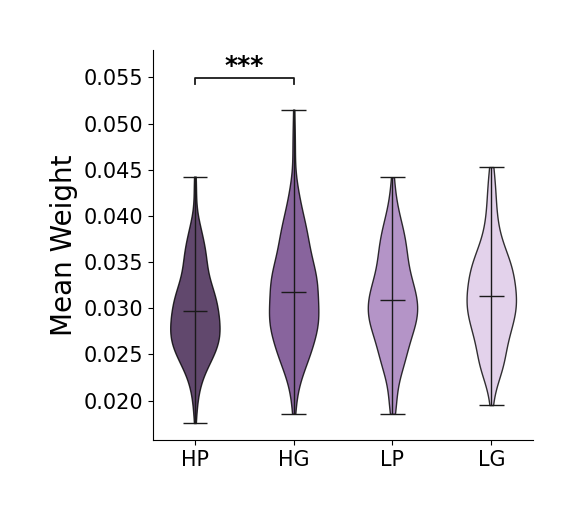

In [16]:
### Compare groups on risk- and health-aligned edges and create Figure 5b ###

group_stats = compare_matched_groups(matched_df, save_path=save_dir)

In [17]:
### Connection hemisphere location and type (rich, feeder, local) analysis ##

hemisphere_location(aligned_overlap_masks['Mental Health & Genetics'], region_labels, group='M&G')

connection_type(aligned_overlap_masks['Mental Health & Genetics'], rich_club, group='M&G')


Hemisphere location (M&G)
    Risk-aligned   left =  31.0%  right =  21.2%  inter =  47.8%
    Health-aligned left =  26.5%  right =  26.5%  inter =  46.9%
Connection type (M&G)
    Risk-aligned   rich =   1.4%  feeder =  19.1%  local =  79.4%
    Health-aligned rich =   0.4%  feeder =  18.6%  local =  80.9%


    region          risk%  health%   diff%        p
    OrG_R            1.74     5.15   -3.41   0.0002  Health-leaning ***
    ITG_L            3.19     0.88   +2.31   0.0022  Risk-leaning **
    BG_R             1.74     3.84   -2.10   0.0036  Health-leaning **
    PCun_L           2.90     0.88   +2.02   0.0046  Risk-leaning **
    Tha_R            3.04     5.04   -2.00   0.0064  Health-leaning **
    IFG_L            1.59     3.18   -1.59   0.0252  Health-leaning *
    LOcC_L           2.90     1.32   +1.58   0.0288  Risk-leaning *
    CG_L             4.06     2.52   +1.54   0.0338  Risk-leaning *


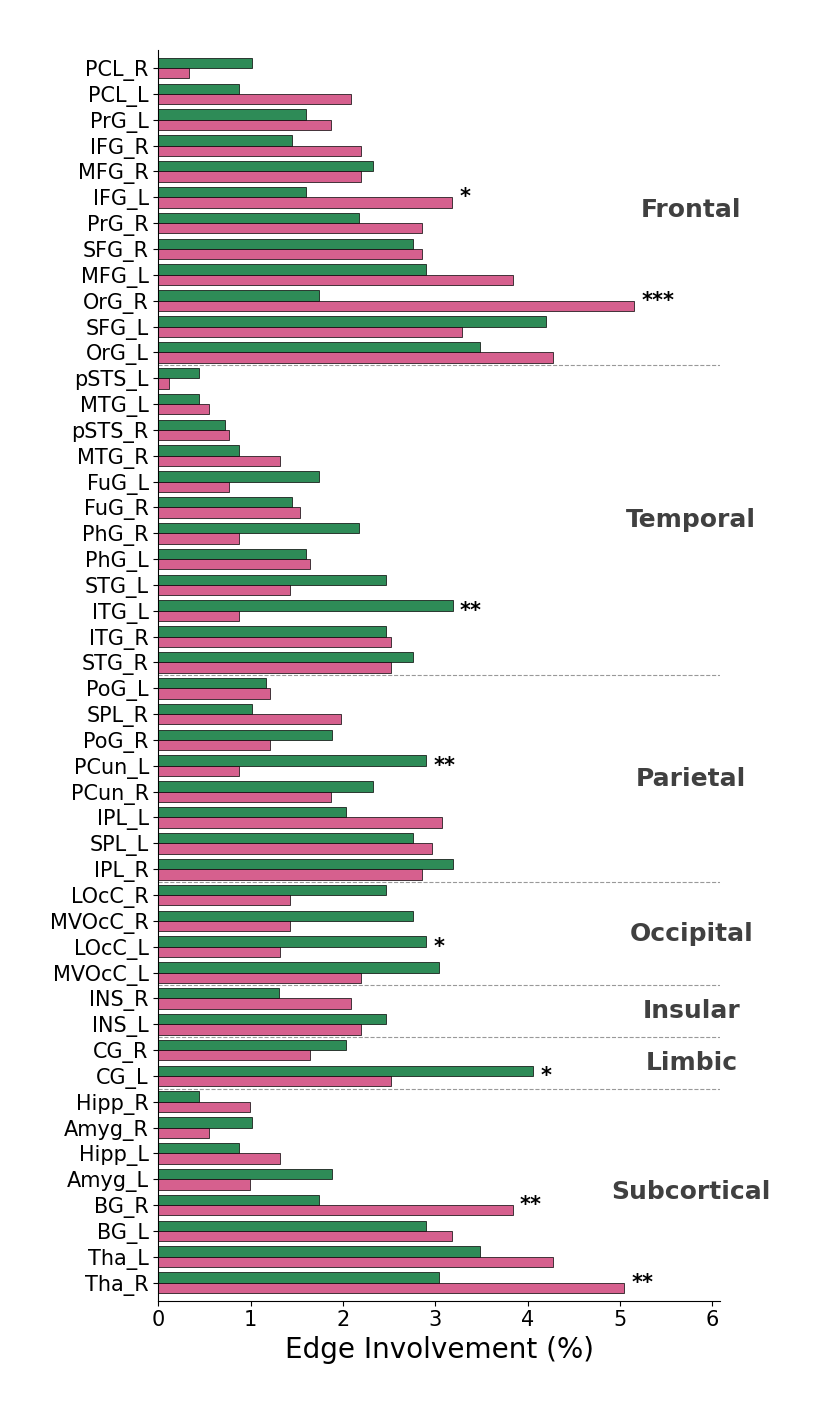

In [18]:
### Edge involvmeent analysis and Figure 5c barplot and circos ###

# Map from 246 regions to 48 general regions (e.g., 'SFG_L_7_1' -> 'SFG_L')
general_regions = np.array(['_'.join(lbl.split('_')[:2]) for lbl in region_labels])  

region_results = region_involvement(mask, general_regions, atlas['lobe'], save_path=save_dir,group='M&G')

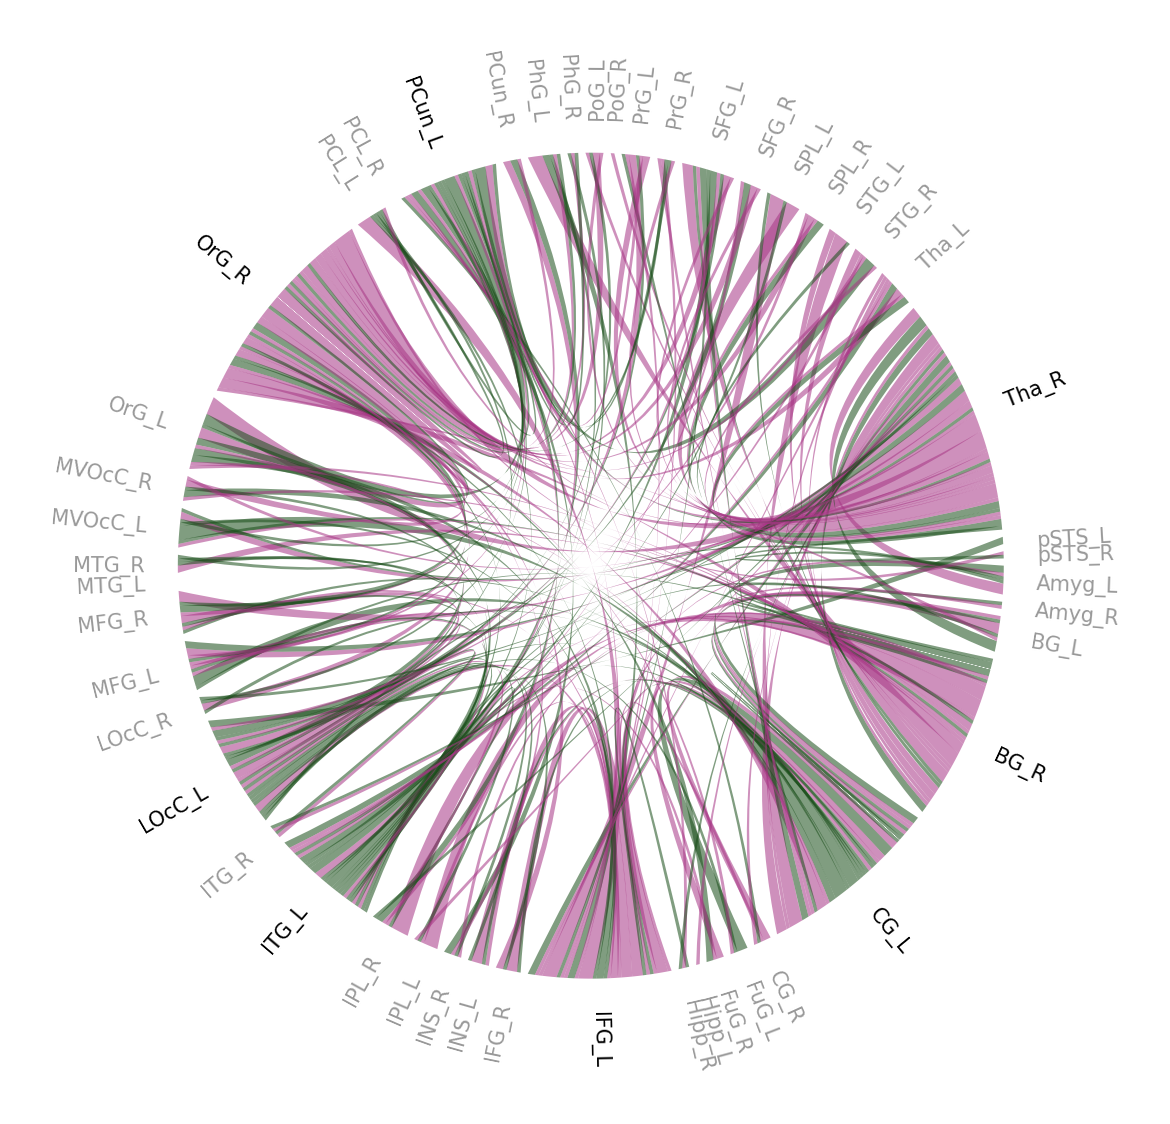

In [19]:
### Plot circos for Figure 5c ###

region_circos(mask, general_regions, region_results, save_path=save_dir, group='M&G')

M&G Risk-aligned edges: 345 -> keeping top 345 (100%): 345 Risk-aligned


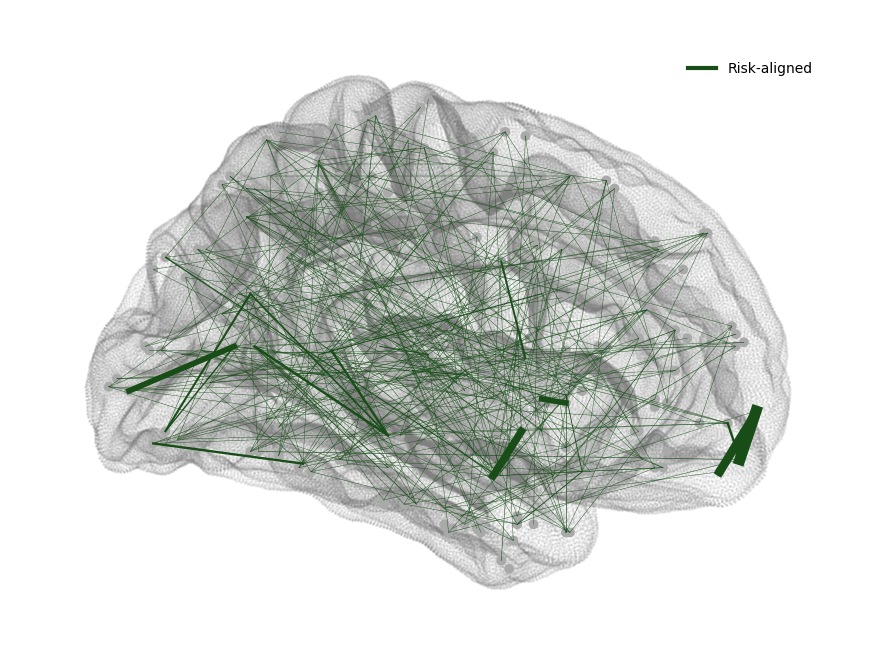

M&G Health-aligned edges: 456 -> keeping top 456 (100%): 456 Health-aligned


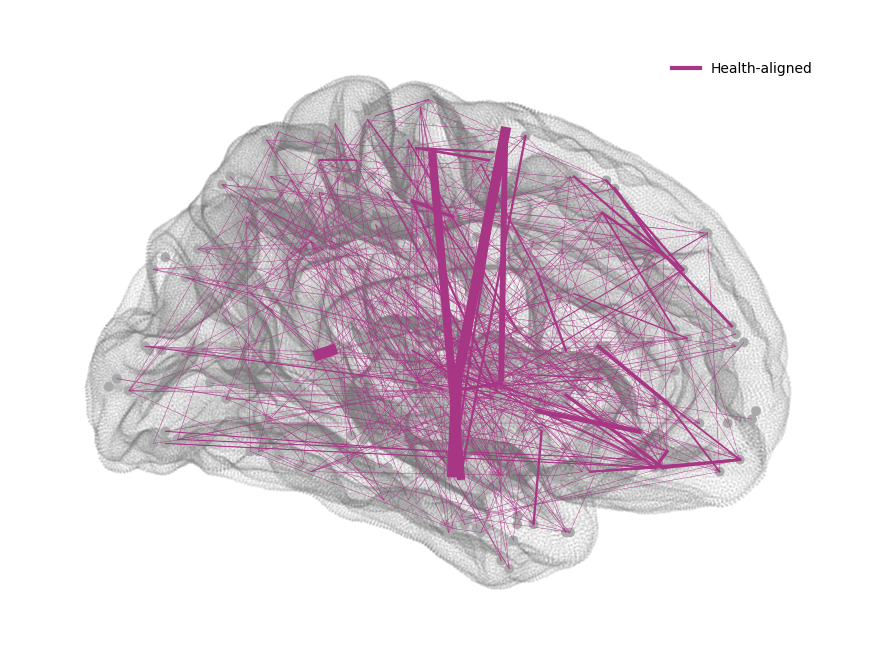

In [20]:
### Figure 5c node plots ###

edge_group_node_plot(mask,keep_fraction=1,weight_matrix=mental_health_edge_matrix,plot_args=plot_args,
                     connectomes=connectomes,group='M&G', type='Risk', save_name='M&G_risk_node_plot.pdf')

edge_group_node_plot(mask,keep_fraction=1,weight_matrix=mental_health_edge_matrix,plot_args=plot_args,
                     connectomes=connectomes,group='M&G', type='Health', save_name='M&G_health_node_plot.pdf')
